In [1]:
pip install ipywidgets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt


In [10]:
dataset_dir = "../preprocessed/dataset_splits"


3. Define a Custom Dataset

In [11]:
class LungNoduleDataset(Dataset):
    def __init__(self, split):
        self.folder = os.path.join(dataset_dir, split)
        self.files = [os.path.join(self.folder, f) for f in os.listdir(self.folder) if f.endswith(".npz")]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        patch = data['patch']
        label = data['label']
        
        # Convert to torch tensors
        patch = torch.tensor(patch, dtype=torch.float32).unsqueeze(0)  # add channel dim
        label = torch.tensor(label, dtype=torch.long)
        return patch, label


4. Define a Simple 3D CNN Model

In [12]:
class Simple3DCNN(nn.Module):
    def __init__(self):
        super(Simple3DCNN, self).__init__()
        self.conv1 = nn.Conv3d(1, 32, 3, padding=1)
        self.pool = nn.MaxPool3d(2)
        self.conv2 = nn.Conv3d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 16 * 16 * 16, 128)  # assuming input is 64x64x64
        self.fc2 = nn.Linear(128, 2)  # 2 classes

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x


5. Load Data

In [13]:
train_dataset = LungNoduleDataset(split="train")
val_dataset = LungNoduleDataset(split="val")
test_dataset = LungNoduleDataset(split="test")

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)


6. Set up Model, Loss, Optimizer

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Simple3DCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


7. Training Loop

In [17]:
num_epochs = 20
best_val_loss = float("inf")

# ✅ Initialize lists to save history
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0

    for patches, labels in train_loader:
        patches, labels = patches.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(patches)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for patches, labels in val_loader:
            patches, labels = patches.to(device), labels.to(device)
            outputs = model(patches)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    val_acc = correct / total

    # ✅ Save metrics
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("✅ Best model saved.")


Epoch [1/20], Train Loss: 0.0614, Val Loss: 0.0563, Val Acc: 1.0000
✅ Best model saved.
Epoch [2/20], Train Loss: 0.0246, Val Loss: 0.1993, Val Acc: 0.9310
Epoch [3/20], Train Loss: 0.0072, Val Loss: 0.0466, Val Acc: 1.0000
✅ Best model saved.
Epoch [4/20], Train Loss: 0.0036, Val Loss: 0.0751, Val Acc: 0.9310
Epoch [5/20], Train Loss: 0.0026, Val Loss: 0.0613, Val Acc: 0.9655
Epoch [6/20], Train Loss: 0.0020, Val Loss: 0.0931, Val Acc: 0.9310
Epoch [7/20], Train Loss: 0.0019, Val Loss: 0.0515, Val Acc: 0.9655
Epoch [8/20], Train Loss: 0.0016, Val Loss: 0.1054, Val Acc: 0.9310
Epoch [9/20], Train Loss: 0.0013, Val Loss: 0.0975, Val Acc: 0.9310
Epoch [10/20], Train Loss: 0.0011, Val Loss: 0.0700, Val Acc: 0.9655
Epoch [11/20], Train Loss: 0.0011, Val Loss: 0.0645, Val Acc: 0.9655
Epoch [12/20], Train Loss: 0.0014, Val Loss: 0.1205, Val Acc: 0.9310
Epoch [13/20], Train Loss: 0.0009, Val Loss: 0.0980, Val Acc: 0.9310
Epoch [14/20], Train Loss: 0.0007, Val Loss: 0.0983, Val Acc: 0.9310
Epo

8. Final Testing

In [18]:
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for patches, labels in test_loader:
        patches, labels = patches.to(device), labels.to(device)
        outputs = model(patches)
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

avg_test_loss = test_loss / len(test_loader)
test_acc = correct / total

print(f"Test Loss: {avg_test_loss:.4f}, Test Accuracy: {test_acc:.4f}")


Test Loss: 0.5722, Test Accuracy: 0.8333


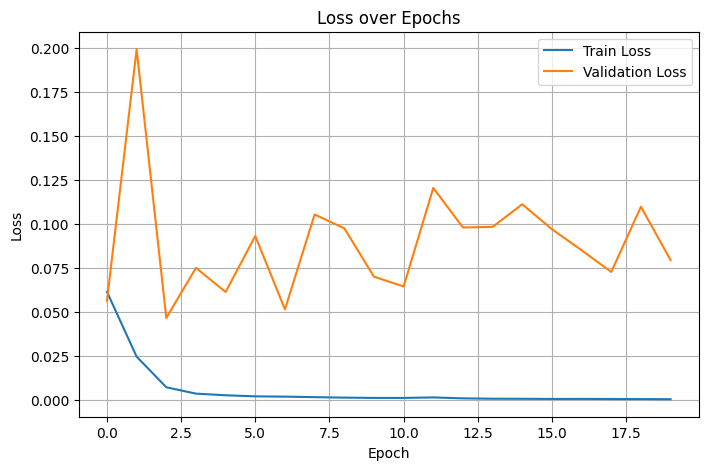

In [32]:
# 📈 Plot Loss over Epochs

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


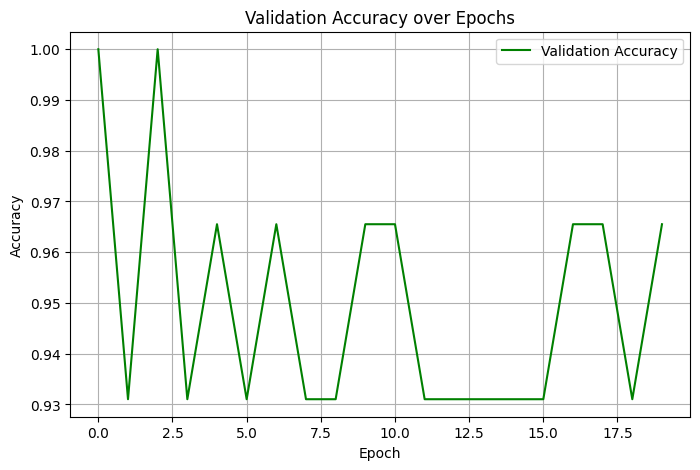

In [35]:
# 📈 Plot Validation Accuracy

plt.figure(figsize=(8, 5))
plt.plot(val_accuracies, label='Validation Accuracy', color='green')
plt.title('Validation Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [19]:
activations = {}
gradients = {}


In [20]:
def forward_hook(module, input, output):
    activations['value'] = output

def backward_hook(module, grad_input, grad_output):
    gradients['value'] = grad_output[0]


In [21]:
target_layer = model.conv2  # The second convolution layer

target_layer.register_forward_hook(forward_hook)
target_layer.register_backward_hook(backward_hook)


In [22]:
# Forward
sample_patch, sample_label = test_dataset[0]
sample_patch = sample_patch.unsqueeze(0).to(device)
output = model(sample_patch)
pred_label = output.argmax(dim=1)

# Backward
model.zero_grad()
class_loss = output[0, pred_label]
class_loss.backward()


C:\Users\mahdi\anaconda3\envs\tf-patch\lib\site-packages\torch\nn\modules\module.py:1830: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


In [23]:
act = activations['value'].squeeze(0).cpu().detach().numpy()   # (C, D, H, W)
grad = gradients['value'].squeeze(0).cpu().detach().numpy()    # (C, D, H, W)

# ... (same weighted sum, ReLU, normalization steps)


In [24]:
# Compute weights by global average pooling the gradients
weights = np.mean(grad, axis=(1, 2, 3))  # (C,)

# Weighted sum of the activations
cam = np.zeros(act.shape[1:], dtype=np.float32)  # (D, H, W)

for i, w in enumerate(weights):
    cam += w * act[i]

# Apply ReLU (keep only positive influence)
cam = np.maximum(cam, 0)

# Normalize CAM to [0, 1]
cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam) + 1e-8)


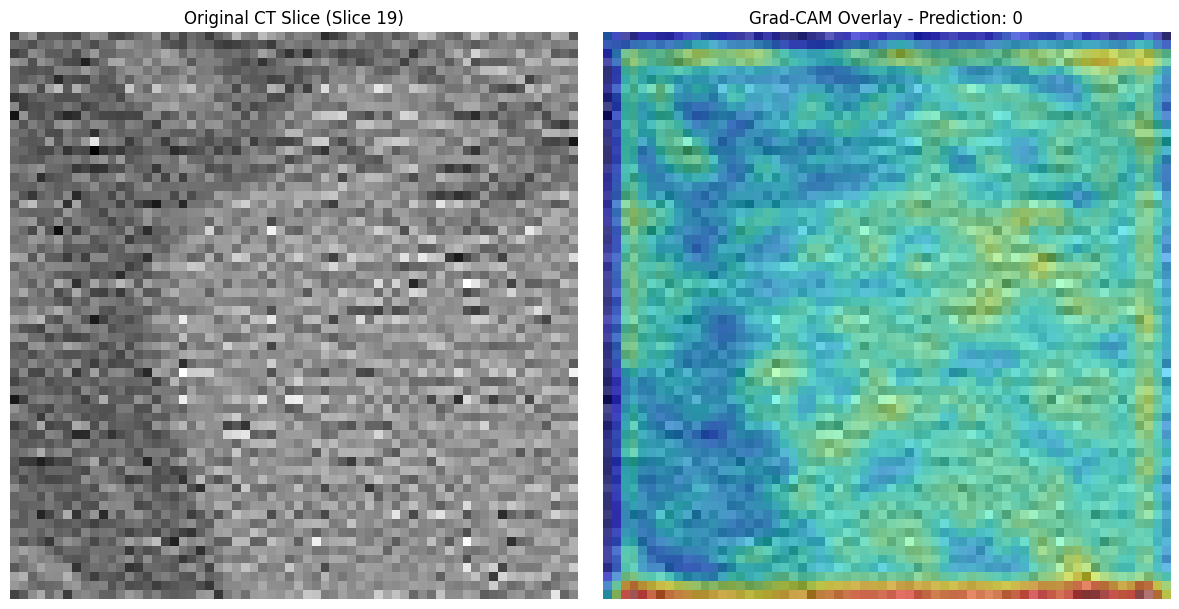

In [42]:
from scipy.ndimage import zoom
import matplotlib.pyplot as plt
import numpy as np

# Prepare patch
patch_np = sample_patch.squeeze().cpu().numpy()

# Upsample the cam to match the patch size
depth_scale = patch_np.shape[0] / cam.shape[0]
height_scale = patch_np.shape[1] / cam.shape[1]
width_scale = patch_np.shape[2] / cam.shape[2]

cam_resized = zoom(cam, (depth_scale, height_scale, width_scale))

# Pick a random slice instead of middle slice
random_slice_idx = np.random.randint(0, patch_np.shape[0])

plt.figure(figsize=(12,6))

# Original CT slice
plt.subplot(1,2,1)
plt.imshow(patch_np[random_slice_idx, :, :], cmap='gray')
plt.title(f"Original CT Slice (Slice {random_slice_idx})")
plt.axis('off')

# Grad-CAM overlay
plt.subplot(1,2,2)
plt.imshow(patch_np[random_slice_idx, :, :], cmap='gray')
plt.imshow(cam_resized[random_slice_idx, :, :], cmap='jet', alpha=0.5)
plt.title(f"Grad-CAM Overlay - Prediction: {pred_label.item()}")
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider


In [ ]:
# Scrolling through CT slices with Grad-CAM overlay

def plot_slice(slice_idx):
    plt.figure(figsize=(12,6))
    
    # Original CT slice
    plt.subplot(1,2,1)
    plt.imshow(patch_np[slice_idx, :, :], cmap='gray')
    plt.title(f"Original CT Slice (Slice {slice_idx})")
    plt.axis('off')
    
    # Grad-CAM overlay
    plt.subplot(1,2,2)
    plt.imshow(patch_np[slice_idx, :, :], cmap='gray')
    plt.imshow(cam_resized[slice_idx, :, :], cmap='jet', alpha=0.5)
    plt.title(f"Grad-CAM Overlay (Slice {slice_idx})")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()


In [26]:
from ipywidgets import interactive, IntSlider
from IPython.display import display

def plot_slice(slice_idx):
    plt.figure(figsize=(12,6))

    # Original CT slice
    plt.subplot(1,2,1)
    plt.imshow(patch_np[slice_idx, :, :], cmap='gray')
    plt.title(f"Original CT Slice (Slice {slice_idx})")
    plt.axis('off')

    # Grad-CAM overlay
    plt.subplot(1,2,2)
    plt.imshow(patch_np[slice_idx, :, :], cmap='gray')
    plt.imshow(cam_resized[slice_idx, :, :], cmap='jet', alpha=0.5)
    plt.title(f"Grad-CAM Overlay (Slice {slice_idx})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Create and display
slider = interactive(plot_slice, slice_idx=IntSlider(min=0, max=patch_np.shape[0]-1, step=1, value=patch_np.shape[0]//2))
display(slider)


interactive(children=(IntSlider(value=32, description='slice_idx', max=63), Output()), _dom_classes=('widget-i…

In [27]:
import ipywidgets as widgets


In [28]:
import imageio
import os
from tqdm import tqdm
import matplotlib.pyplot as plt


In [29]:
output_folder = "gradcam_slices"

# Create the output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)


In [30]:
start_slice = 16  # 📢 start from slice 16!

for slice_idx in tqdm(range(start_slice, patch_np.shape[0]), desc="Saving slices"):
    plt.figure(figsize=(8, 8))
    
    plt.imshow(patch_np[slice_idx, :, :], cmap='gray')
    plt.imshow(cam_resized[slice_idx, :, :], cmap='jet', alpha=0.5)
    plt.axis('off')
    plt.title(f"Slice {slice_idx}")
    
    filename = os.path.join(output_folder, f"slice_{slice_idx:03d}.png")
    plt.savefig(filename, bbox_inches='tight', pad_inches=0)
    plt.close()


Saving slices: 100%|███████████████████████████████████████████████████████████████████| 48/48 [00:14<00:00,  3.24it/s]


In [31]:
# Read all saved images starting from slice 16
images = []
for slice_idx in range(start_slice, patch_np.shape[0]):
    filename = os.path.join(output_folder, f"slice_{slice_idx:03d}.png")
    images.append(imageio.imread(filename))

# Save all images into a GIF
gif_filename = "gradcam_scroll.gif"
imageio.mimsave(gif_filename, images, duration=0.4)  # 0.1 sec per frame


C:\Users\mahdi\AppData\Local\Temp\ipykernel_4112\2258408168.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(filename))
